# Automatic Photo Albums with a Pre-trained CNN
**Jamel Lawson, SENG 691, Assignment 5 (HW5): Neural Networks and Deep Learning**

This notebook builds a complete automatic photo album system:

1. A dataset of 240 photographs collected from Wikimedia Commons (the collection script is `src/collect_dataset.py`; every image is logged with creator and license in `data/manifest.csv`).
2. Feature extraction with a pre-trained ResNet-50 (transfer learning).
3. Unsupervised grouping with K-Means, scored with silhouette, purity, and NMI.
4. Background music synthesized in code and selected per cluster by a fixed algorithmic rule over the cluster's visual statistics.
5. Slideshow videos rendered with FFmpeg.

Requirements are in `README.md`. Heavy steps cache their results under `output/`, so re-running the notebook reuses the cached features and statistics when they exist.

## Setup (run this first, especially in Google Colab)

This notebook expects the project files (`data/manifest.csv`) and the 240 photos in `data/images/`. Opening the notebook from GitHub loads only the notebook itself, so in Colab this cell clones the private repository (using a read-only GitHub token saved in Colab Secrets as `GITHUB_TOKEN`) and downloads the photos from the Wikimedia Commons URLs listed in the manifest. On a local machine with the dataset already present, it changes nothing.

In [ ]:
# --- Setup: project files and photo dataset (safe to re-run) ---
import csv, os, shutil, subprocess, sys, urllib.request
from pathlib import Path

def _fetch(url, dest, tries=4):
    """Download url to dest in chunks, checking the byte count, with
    retries, so one dropped connection cannot stop the whole dataset."""
    for attempt in range(tries):
        try:
            req = urllib.request.Request(
                url, headers={"User-Agent": "SENG691-HW5/1.0 (student project)"})
            with urllib.request.urlopen(req) as resp:
                total = resp.headers.get("Content-Length")
                chunks = []
                while True:
                    chunk = resp.read(1 << 16)
                    if not chunk:
                        break
                    chunks.append(chunk)
            data = b"".join(chunks)
            if total is not None and len(data) != int(total):
                raise OSError(f"short download: {len(data)} of {total} bytes")
            part = dest.with_name(dest.name + ".part")
            part.write_bytes(data)
            part.replace(dest)
            return
        except Exception:
            if attempt == tries - 1:
                raise

if "google.colab" in sys.modules and not Path("data/manifest.csv").exists():
    if Path("seng691-hw5/data/manifest.csv").exists():
        os.chdir("seng691-hw5")  # reuse the clone from an earlier run
        print("project folder:", Path.cwd())
    else:
        from google.colab import userdata
        try:
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
        if not token:
            raise RuntimeError(
                "The GITHUB_TOKEN secret was not found, so the private repo "
                "cannot be cloned. In Colab, open Secrets (the key icon on "
                "the left), add a secret named GITHUB_TOKEN with your "
                "fine-grained GitHub token, turn on Notebook access for it, "
                "then run this cell again.")
        if Path("seng691-hw5").exists():
            shutil.rmtree("seng691-hw5")  # clear a partial earlier attempt
        url = f"https://{token}@github.com/jamelski1/seng691-hw5.git"
        result = subprocess.run(["git", "clone", "--quiet", url],
                                capture_output=True, text=True)
        if result.returncode != 0:
            raise RuntimeError("git clone failed: "
                               + result.stderr.replace(token, "***"))
        os.chdir("seng691-hw5")
        print("project folder:", Path.cwd())

if Path("data/manifest.csv").exists():
    _rows = list(csv.DictReader(open("data/manifest.csv")))
    _missing = [r for r in _rows
                if not Path("data/images", r["file"]).exists()]
    if _missing:
        print(f"downloading {len(_missing)} photos from Wikimedia Commons...")
        for _i, _r in enumerate(_rows, 1):
            _dest = Path("data/images", _r["file"])
            if _dest.exists():
                continue
            _dest.parent.mkdir(parents=True, exist_ok=True)
            _fetch(_r["image_url"], _dest)
            if _i % 40 == 0:
                print(f"  {_i} of {len(_rows)} photos checked")
        print("dataset ready:", len(_rows), "photos")
    else:
        print("dataset already present:", len(_rows), "photos")


In [1]:
import csv, json
from collections import Counter
from pathlib import Path

import numpy as np
from PIL import Image

BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)
print("project folder:", BASE)

project folder: /home/hatch/workspace/seng691-hw5


## 1. The dataset

240 freely licensed photographs from Wikimedia Commons, 30 each across eight seed topics. The topics were used only to assemble a varied set and to check the clustering afterwards. The clustering never sees them.

In [2]:
rows = list(csv.DictReader(open(DATA / "manifest.csv")))
print("images:", len(rows))
print("per topic:", dict(Counter(r["seed_topic"] for r in rows)))
print("licenses:", dict(Counter(r["license"] for r in rows).most_common(4)))
widths = [int(r["width"]) for r in rows]
heights = [int(r["height"]) for r in rows]
print("widths: all", set(widths), "| heights min/median/max:",
      min(heights), int(np.median(heights)), max(heights))

images: 240
per topic: {'mountains': 30, 'beach': 30, 'city': 30, 'forest': 30, 'desert': 30, 'snow': 30, 'dogs': 30, 'flowers': 30}
licenses: {'CC BY-SA 4.0': 101, 'Public domain': 37, 'CC BY-SA 3.0': 35, 'CC BY 4.0': 26}
widths: all {1920} | heights min/median/max: 504 1280 3412


### Initial dataset analysis

Before any learning, each image is described by four simple statistics that the music rule will also use later: brightness, saturation, warm/cool balance, and edge density (how much fine detail the image has).

In [3]:
def visual_stats(path):
    img = Image.open(path).convert("RGB").resize((128, 128))
    arr = np.asarray(img).astype(np.float32) / 255.0
    r, b = arr[..., 0], arr[..., 2]
    mx, mn = arr.max(axis=2), arr.min(axis=2)
    gray = arr.mean(axis=2)
    return {
        "brightness": float(mx.mean()),
        "saturation": float((((mx - mn) / np.maximum(mx, 1e-6))[mx > 0]).mean()),
        "warmth": float(r.mean() - b.mean()),
        "edge_density": float(np.abs(np.diff(gray, axis=1)).mean()
                              + np.abs(np.diff(gray, axis=0)).mean()),
    }

stats_file = OUT / "image_stats.csv"
if stats_file.exists():
    stats = {r["file"]: {k: float(r[k]) for k in
             ("brightness", "saturation", "warmth", "edge_density")}
             for r in csv.DictReader(open(stats_file))}
else:
    stats = {}
    for r in rows:
        stats[r["file"]] = visual_stats(DATA / "images" / r["file"])
    with open(stats_file, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["file", "seed_topic", "brightness", "saturation",
                    "warmth", "edge_density"])
        for r in rows:
            s = stats[r["file"]]
            w.writerow([r["file"], r["seed_topic"], s["brightness"],
                        s["saturation"], s["warmth"], s["edge_density"]])

topics = sorted({r["seed_topic"] for r in rows})
print(f"{'topic':<11}{'bright':>7}{'satur':>7}{'warm':>7}{'edge':>7}")
for t in topics:
    sel = [stats[r["file"]] for r in rows if r["seed_topic"] == t]
    print(f"{t:<11}" + "".join(
        f"{np.mean([s[k] for s in sel]):>7.3f}"
        for k in ("brightness", "saturation", "warmth", "edge_density")))

topic       bright  satur   warm   edge
beach        0.651  0.260 -0.005  0.055
city         0.568  0.267 -0.080  0.066
desert       0.693  0.462  0.240  0.053
dogs         0.471  0.199  0.063  0.072
flowers      0.492  0.457  0.110  0.097
forest       0.430  0.318  0.054  0.110
mountains    0.556  0.292 -0.005  0.073
snow         0.660  0.220 -0.035  0.065


## 2. Feature extraction with a pre-trained CNN

Each image becomes the 2048 numbers produced by a pre-trained ResNet-50 just before its classification layer. The network learned general visual structure from over a million ImageNet images, so its features separate scenes by content, not just color, which is exactly what grouping needs and what a dataset of 240 images could never train from scratch. Vectors are scaled to unit length so that closeness means cosine similarity.

In [4]:
feat_file = OUT / "features.npz"
if feat_file.exists():
    saved = np.load(feat_file)
    X, files = saved["X"], list(saved["files"])
    print("loaded cached embeddings:", X.shape)
else:
    import torch
    from torchvision import models

    weights = models.ResNet50_Weights.IMAGENET1K_V2
    model = models.resnet50(weights=weights)
    model.fc = torch.nn.Identity()
    model.eval()
    preprocess = weights.transforms()
    files = [r["file"] for r in rows]
    feats = []
    with torch.no_grad():
        for i in range(0, len(files), 16):
            batch = [preprocess(Image.open(DATA / "images" / f).convert("RGB"))
                     for f in files[i:i + 16]]
            feats.append(model(torch.stack(batch)).numpy())
    X = np.vstack(feats)
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    np.savez(feat_file, X=X, files=np.array(files),
             topics=np.array([r["seed_topic"] for r in rows]))
    print("extracted embeddings:", X.shape)

labels_true = [next(r["seed_topic"] for r in rows if r["file"] == f) for f in files]

loaded cached embeddings: (240, 2048)


## 3. Clustering

K-Means is run for every cluster count from 4 to 10 and the count with the best silhouette score wins. Agglomerative clustering at the same count checks that the structure is not one algorithm's artifact. Purity and NMI then grade the result against the seed topics the clustering never saw.

In [5]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, normalized_mutual_info_score

def purity_score(y_true, y_pred):
    correct = 0
    for c in set(y_pred):
        members = [t for t, p in zip(y_true, y_pred) if p == c]
        correct += Counter(members).most_common(1)[0][1]
    return correct / len(y_true)

fits = {}
for k in range(4, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    fits[k] = km
    print(f"k={k}: silhouette={silhouette_score(X, km.labels_):.3f}")

best_k = max(fits, key=lambda k: silhouette_score(X, fits[k].labels_))
km = fits[best_k]
labels = km.labels_
agg = AgglomerativeClustering(n_clusters=best_k).fit(X)
print(f"\nchosen k = {best_k}")
print(f"agglomerative silhouette at k={best_k}: "
      f"{silhouette_score(X, agg.labels_):.3f}")
print(f"purity vs seed topics: {purity_score(labels_true, labels):.3f}")
print(f"NMI vs seed topics:    {normalized_mutual_info_score(labels_true, labels):.3f}")

k=4: silhouette=0.106


k=5: silhouette=0.120


k=6: silhouette=0.137


k=7: silhouette=0.144


k=8: silhouette=0.150


k=9: silhouette=0.143


k=10: silhouette=0.141



chosen k = 8
agglomerative silhouette at k=8: 0.147
purity vs seed topics: 0.821
NMI vs seed topics:    0.739


In [6]:
stat_keys = ("brightness", "saturation", "warmth", "edge_density")
S = {k: np.array([stats[f][k] for f in files]) for k in stat_keys}
clusters = []
for c in range(best_k):
    idx = np.where(labels == c)[0]
    mix = Counter(labels_true[i] for i in idx)
    dominant, dom_n = mix.most_common(1)[0]
    info = {"cluster": c, "size": len(idx), "dominant": dominant,
            "share": dom_n / len(idx), "mix": dict(mix.most_common())}
    info.update({f"mean_{k}": float(S[k][idx].mean()) for k in stat_keys})
    clusters.append(info)
    print(f"Cluster {c}: {len(idx):>2} images, {dominant} {dom_n / len(idx):.0%}, "
          f"mix={info['mix']}")
    print(f"   brightness {info['mean_brightness']:.2f}, saturation "
          f"{info['mean_saturation']:.2f}, warmth {info['mean_warmth']:+.2f}, "
          f"edge {info['mean_edge_density']:.3f}")

Cluster 0: 31 images, dogs 97%, mix={'dogs': 30, 'snow': 1}
   brightness 0.48, saturation 0.20, warmth +0.06, edge 0.071
Cluster 1: 19 images, beach 100%, mix={'beach': 19}
   brightness 0.69, saturation 0.21, warmth -0.07, edge 0.055
Cluster 2: 27 images, city 96%, mix={'city': 26, 'beach': 1}
   brightness 0.57, saturation 0.27, warmth -0.09, edge 0.062
Cluster 3: 42 images, forest 67%, mix={'forest': 28, 'beach': 6, 'flowers': 5, 'mountains': 2, 'snow': 1}
   brightness 0.47, saturation 0.35, warmth +0.09, edge 0.103
Cluster 4: 38 images, mountains 71%, mix={'mountains': 27, 'snow': 9, 'beach': 2}
   brightness 0.57, saturation 0.30, warmth -0.04, edge 0.068
Cluster 5: 30 images, desert 90%, mix={'desert': 27, 'beach': 2, 'mountains': 1}
   brightness 0.69, saturation 0.45, warmth +0.23, edge 0.048
Cluster 6: 22 images, flowers 95%, mix={'flowers': 21, 'desert': 1}
   brightness 0.48, saturation 0.47, warmth +0.09, edge 0.088
Cluster 7: 31 images, snow 61%, mix={'snow': 19, 'city':

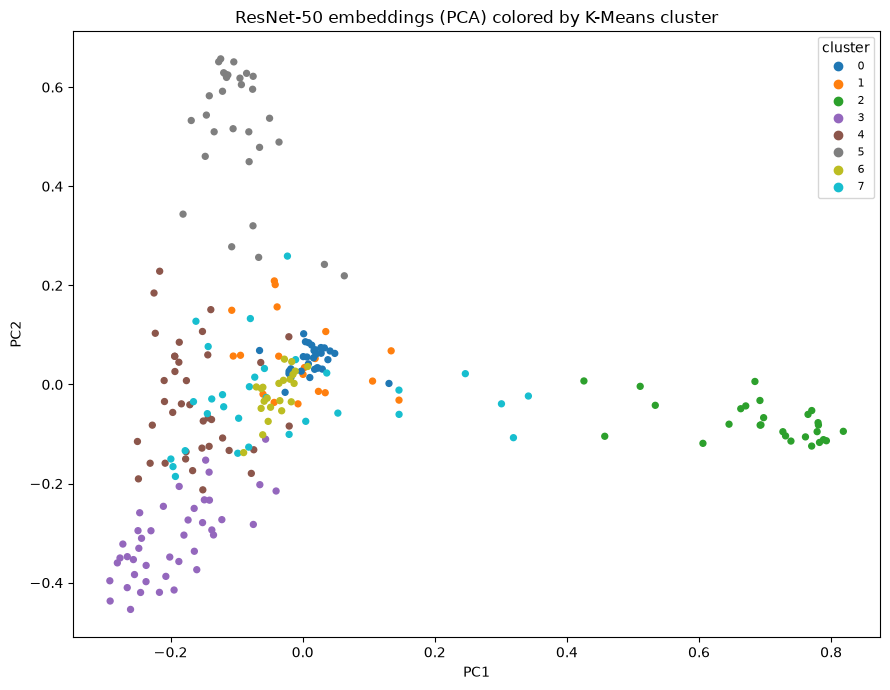

In [7]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

XY = PCA(n_components=2, random_state=0).fit_transform(X)
plt.figure(figsize=(9, 7))
sc = plt.scatter(XY[:, 0], XY[:, 1], c=labels, cmap="tab10", s=18)
plt.legend(*sc.legend_elements(), title="cluster", fontsize=8)
plt.title("ResNet-50 embeddings (PCA) colored by K-Means cluster")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

Contact sheets of the twelve images closest to two cluster centers. Cluster 0 is almost purely dog portraits; Cluster 3 is the greenery cluster.

In [ ]:
# Contact sheets: the 12 images closest to each cluster center.
# (The submitted package got these from src/analyze.py; here the
# notebook builds them itself so it runs standalone.)
for c in range(best_k):
    idx = np.where(labels == c)[0]
    d = np.linalg.norm(X[idx] - km.cluster_centers_[c], axis=1)
    closest = idx[np.argsort(d)][:12]
    thumbs = []
    for i in closest:
        t = Image.open(DATA / "images" / files[i]).convert("RGB")
        t.thumbnail((320, 320))
        thumbs.append(t)
    sheet = Image.new("RGB", (320 * 4, 320 * 3), "white")
    for j, t in enumerate(thumbs):
        sheet.paste(t, ((j % 4) * 320, (j // 4) * 320))
    sheet.save(OUT / f"montage_cluster_{c}.jpg", quality=88)
print("contact sheets saved to", OUT)


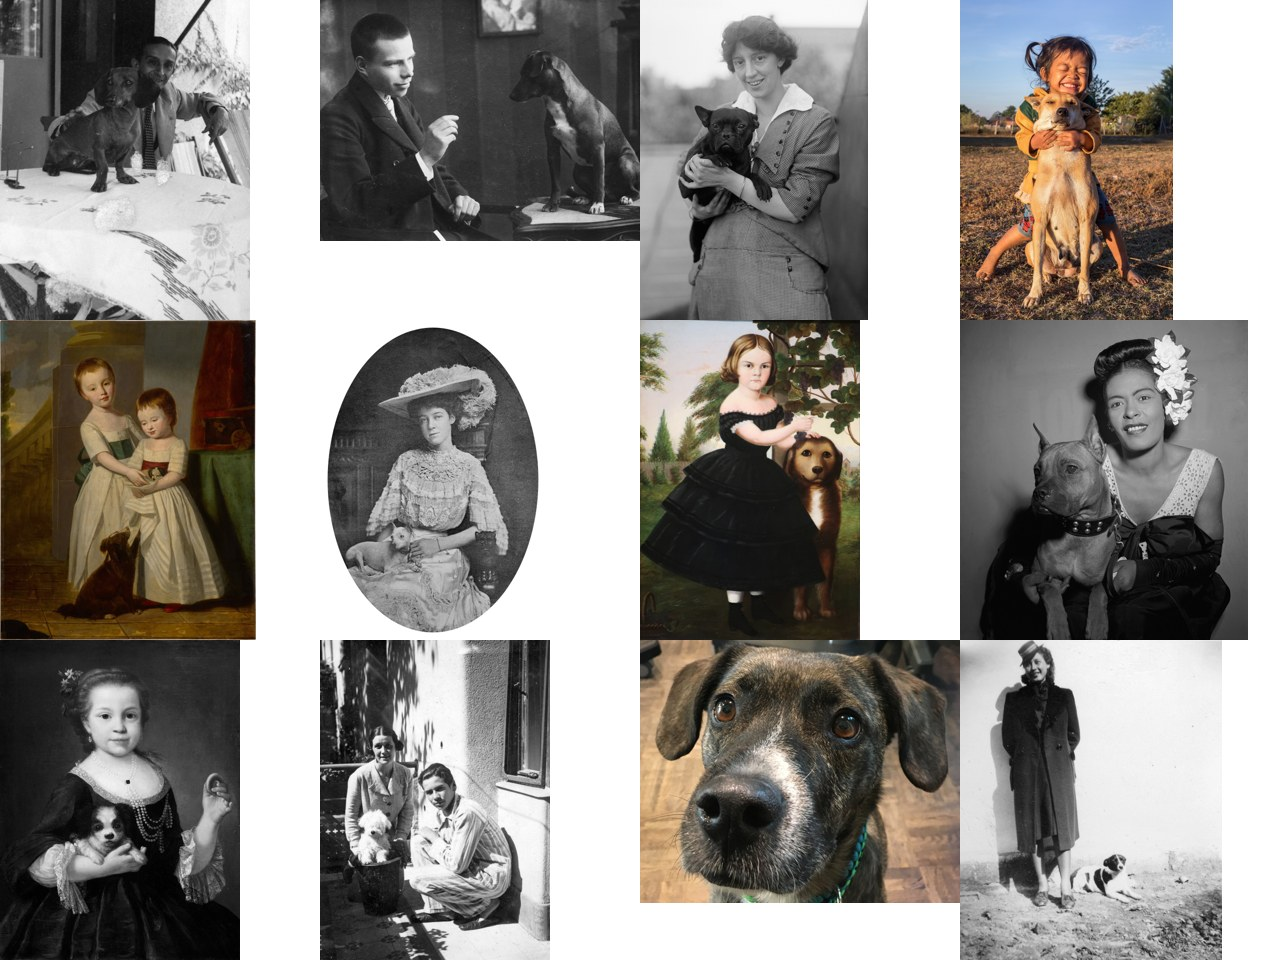

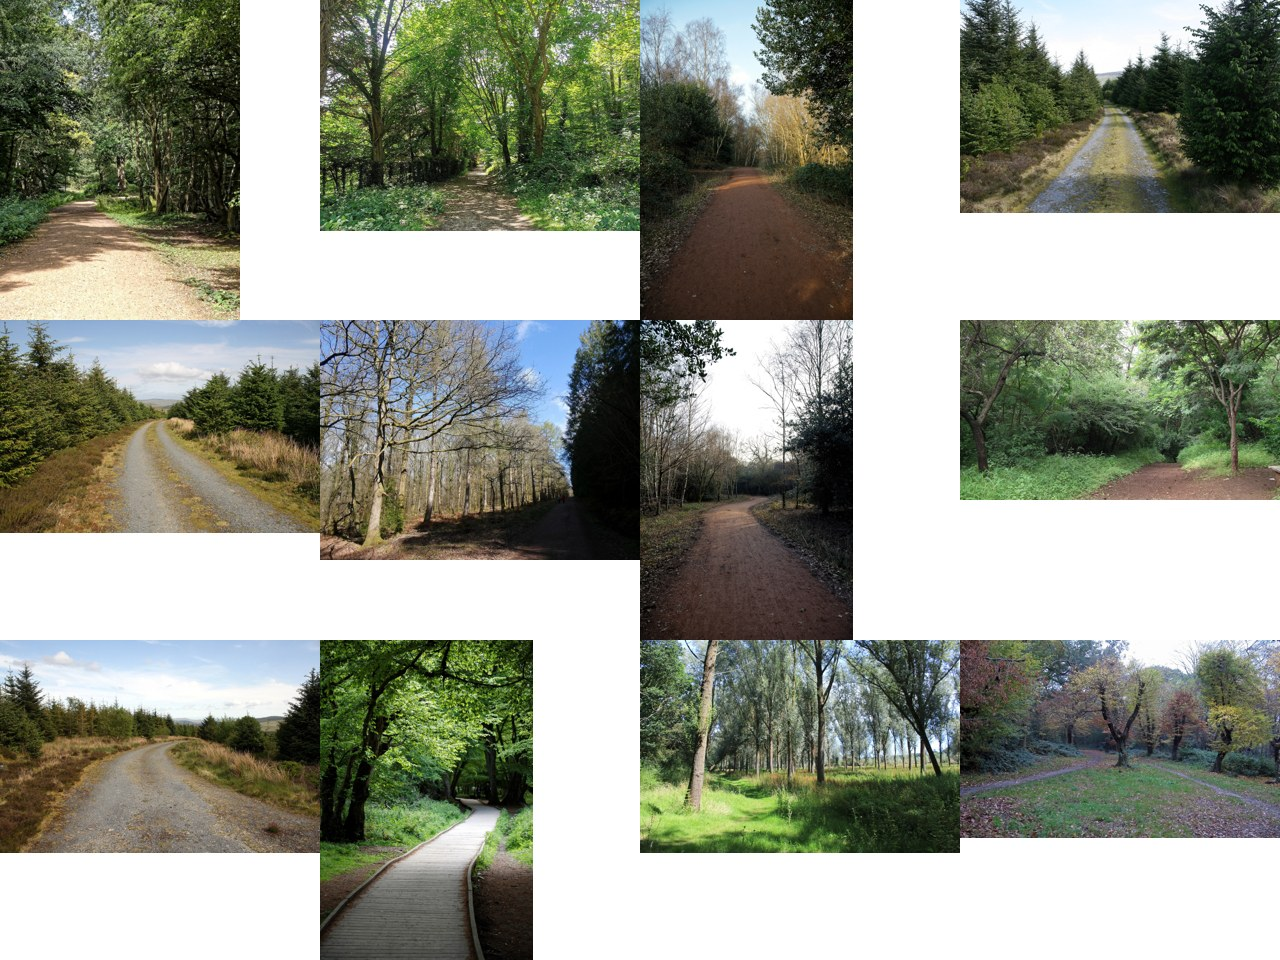

In [8]:
from IPython.display import Image as ShowImage, display
display(ShowImage(str(OUT / "montage_cluster_0.jpg"), width=720))
display(ShowImage(str(OUT / "montage_cluster_3.jpg"), width=720))

## 4. Music, synthesized and selected by rule

Four original tracks are synthesized with NumPy (no copyrighted audio). Each has a profile: tempo, mode, register, timbre, warmth. The selection rule normalizes each cluster's visual statistics across the clusters, builds a target profile (edge density drives tempo, brightness drives register, brightness with saturation drives mode, saturation drives timbre, color balance drives warmth), and picks the track with the smallest weighted distance to the target. Fixed, deterministic, and saved with its scores.

In [9]:
from scipy.io import wavfile

SR = 22050
def freq(st): return 440.0 * 2 ** (st / 12.0)

MAJ = {"C": [-9, -5, -2], "G": [-14, -10, -5], "Am": [-12, -9, -5], "F": [-16, -12, -9]}
MIN = {"Am": [-12, -9, -5], "F": [-16, -12, -9], "C": [-9, -5, -2], "G": [-14, -10, -5]}
P_MAJ = [-9, -7, -5, -2, 0, 3, 5]
P_MIN = [-12, -9, -7, -5, -2, 0, 3]
TRACKS = {
    "calm":     dict(bpm=72,  mode="major", register=0,   timbre=0.25, warmth=0.6,
                     prog=["C", "G", "Am", "F"], chords=MAJ, scale=P_MAJ, dens=0.45, seed=11),
    "bright":   dict(bpm=116, mode="major", register=12,  timbre=0.85, warmth=0.4,
                     prog=["C", "G", "Am", "F"], chords=MAJ, scale=P_MAJ, dens=0.80, seed=23),
    "warm":     dict(bpm=94,  mode="major", register=0,   timbre=0.50, warmth=1.0,
                     prog=["F", "C", "G", "Am"], chords=MAJ, scale=P_MAJ, dens=0.60, seed=37),
    "dramatic": dict(bpm=82,  mode="minor", register=-12, timbre=0.35, warmth=0.2,
                     prog=["Am", "F", "C", "G"], chords=MIN, scale=P_MIN, dens=0.50, seed=41),
}

def tone(st, seconds, kind, gain=0.2):
    t = np.linspace(0, seconds, int(SR * seconds), endpoint=False)
    f = freq(st)
    if kind == "pad":
        w = 0.7 * np.sin(2 * np.pi * f * t) + 0.3 * np.sin(2 * np.pi * 2 * f * t)
        e = np.minimum(1, t / (seconds * 0.3)) * np.minimum(1, (seconds - t) / (seconds * 0.3))
    elif kind == "pluck":
        w = np.sin(2 * np.pi * f * t) + 0.4 * np.sin(2 * np.pi * 2 * f * t)
        e = np.exp(-3.5 * t / seconds)
    else:
        w = np.sin(2 * np.pi * f * t)
        e = np.minimum(1, t / 0.05) * np.minimum(1, (seconds - t) / 0.1)
    return gain * w * e

def synth(spec, target_seconds=46.0):
    bar = 4 * 60.0 / spec["bpm"]
    loops = int(np.ceil(target_seconds / (bar * len(spec["prog"]))))
    audio = np.zeros(int(SR * bar * len(spec["prog"]) * loops))
    rng = np.random.default_rng(spec["seed"])
    pos = 0.0
    for _ in range(loops):
        for name in spec["prog"]:
            tones = spec["chords"][name]
            for st in tones:
                seg = tone(st + spec["register"], bar, "pad", 0.10)
                i = int(pos * SR); audio[i:i + len(seg)] += seg[:len(audio) - i]
            seg = tone(tones[0] - 12 + spec["register"] // 2, bar, "bass", 0.16)
            i = int(pos * SR); audio[i:i + len(seg)] += seg[:len(audio) - i]
            for s in range(8):
                if rng.random() < spec["dens"]:
                    seg = tone(int(rng.choice(spec["scale"])) + 12 + spec["register"],
                               bar / 8 * 1.8, "pluck", 0.12)
                    j = int((pos + s * bar / 8) * SR)
                    audio[j:j + len(seg)] += seg[:len(audio) - j]
            pos += bar
    fade = int(SR * 1.5)
    audio[:fade] *= np.linspace(0, 1, fade)
    audio[-fade:] *= np.linspace(1, 0, fade)
    return audio / np.abs(audio).max() * 0.72

(OUT / "music").mkdir(exist_ok=True)
for name, spec in TRACKS.items():
    wavfile.write(OUT / "music" / f"{name}.wav", SR,
                  (synth(spec) * 32767).astype(np.int16))
    print(f"{name}: {spec['bpm']} BPM, {spec['mode']}")

calm: 72 BPM, major


bright: 116 BPM, major


warm: 94 BPM, major


dramatic: 82 BPM, minor


In [10]:
def track_profile(name):
    s = TRACKS[name]
    return {"tempo_norm": (s["bpm"] - 60) / 70.0,
            "major": 1.0 if s["mode"] == "major" else 0.0,
            "timbre": s["timbre"],
            "register_norm": (s["register"] + 12) / 24.0,
            "warmth": s["warmth"]}

def choose_track(cluster, all_clusters):
    def norm(v, key):
        vals = [c[key] for c in all_clusters]
        lo, hi = min(vals), max(vals)
        return 0.5 if hi <= lo else float(np.clip((v - lo) / (hi - lo), 0, 1))
    bright = norm(cluster["mean_brightness"], "mean_brightness")
    sat = norm(cluster["mean_saturation"], "mean_saturation")
    target = {"tempo_norm": norm(cluster["mean_edge_density"], "mean_edge_density"),
              "major": 0.25 + 0.75 * (bright + sat) / 2.0,
              "timbre": sat, "register_norm": bright,
              "warmth": norm(cluster["mean_warmth"], "mean_warmth")}
    weights = {"tempo_norm": 1.4, "major": 1.2, "timbre": 0.8,
               "register_norm": 0.8, "warmth": 1.0}
    scores = {n: round(float(sum(weights[k] * (track_profile(n)[k] - target[k]) ** 2
                                  for k in weights)), 4) for n in TRACKS}
    return min(scores, key=scores.get), scores

choices = {}
for info in clusters:
    best, scores = choose_track(info, clusters)
    choices[info["cluster"]] = best
    print(f"Cluster {info['cluster']} ({info['dominant']}): -> {best}  {scores}")

Cluster 0 (dogs): -> dramatic  {'calm': 0.9708, 'bright': 2.1778, 'warm': 1.293, 'dramatic': 0.2792}
Cluster 1 (beach): -> calm  {'calm': 0.6395, 'bright': 1.4083, 'warm': 1.5174, 'dramatic': 1.3769}
Cluster 2 (city): -> dramatic  {'calm': 0.6522, 'bright': 1.3731, 'warm': 1.3971, 'dramatic': 0.5233}
Cluster 3 (forest): -> dramatic  {'calm': 1.59, 'bright': 1.3046, 'warm': 1.1245, 'dramatic': 1.0675}
Cluster 4 (mountains): -> calm  {'calm': 0.4785, 'bright': 0.9688, 'warm': 0.937, 'dramatic': 0.5351}
Cluster 5 (desert): -> warm  {'calm': 0.7831, 'bright': 1.2631, 'warm': 0.6861, 'dramatic': 3.0042}
Cluster 6 (flowers): -> warm  {'calm': 1.2225, 'bright': 0.9509, 'warm': 0.7996, 'dramatic': 1.2127}
Cluster 7 (snow): -> calm  {'calm': 0.5527, 'bright': 0.8073, 'warm': 0.8008, 'dramatic': 0.9708}


In [11]:
from IPython.display import Audio, display
print("The track the rule chose for Cluster 3 (greenery):", choices[3])
display(Audio(str(OUT / "music" / f"{choices[3]}.wav")))

The track the rule chose for Cluster 3 (greenery): dramatic


## 5. Slideshow video

The builder takes a cluster's most central images, renders each at 1280 by 720 over a blurred fill of itself (nothing cropped, no black bars), fades between them, and lays the chosen track underneath. Below, Cluster 3 is built and shown; `src/build_videos.py` builds the three largest clusters the same way.

In [12]:
import subprocess, tempfile

def run(cmd): subprocess.run(cmd, check=True, capture_output=True, text=True)

CID = 3
members = [f for f in files if labels[files.index(f)] == CID]
center = X[[files.index(f) for f in members]].mean(axis=0)
center /= np.linalg.norm(center)
members.sort(key=lambda f: -float(X[files.index(f)] @ center))
members = members[:16]
track = choices[CID]
with tempfile.TemporaryDirectory() as td:
    td = Path(td)
    segs = []
    for i, rel in enumerate(members):
        seg = td / f"seg_{i:02d}.mp4"
        vf = ("[0:v]scale=1280:720:force_original_aspect_ratio=increase,"
              "crop=1280:720,boxblur=24:6[bg];"
              "[0:v]scale=1280:720:force_original_aspect_ratio=decrease[fg];"
              "[bg][fg]overlay=(W-w)/2:(H-h)/2,"
              "fade=t=in:st=0:d=0.4,fade=t=out:st=2.2:d=0.4,format=yuv420p")
        run(["ffmpeg", "-y", "-loop", "1", "-t", "2.6", "-i",
             str(DATA / "images" / rel), "-filter_complex", vf, "-r", "30",
             "-c:v", "libx264", "-preset", "veryfast", "-crf", "22", str(seg)])
        segs.append(seg)
    (td / "list.txt").write_text("".join(f"file '{s}'\n" for s in segs))
    run(["ffmpeg", "-y", "-f", "concat", "-safe", "0", "-i",
         str(td / "list.txt"), "-c", "copy", str(td / "joined.mp4")])
    run(["ffmpeg", "-y", "-i", str(td / "joined.mp4"), "-i",
         str(OUT / "music" / f"{track}.wav"), "-c:v", "copy", "-c:a", "aac",
         "-b:a", "160k", "-af", "afade=t=out:st=39.6:d=2", "-shortest",
         str(OUT / f"slideshow_cluster_{CID}.mp4")])
print("built slideshow_cluster_3.mp4 with music:", track)

built slideshow_cluster_3.mp4 with music: dramatic


In [13]:
from IPython.display import Video, display
display(Video(str(OUT / "slideshow_cluster_3.mp4"), width=720,
              html_attributes="controls muted"))

## 6. Conclusion

The unsupervised pipeline recovers the structure of the collection: silhouette peaks at the same eight groups the dataset was seeded with, purity is 0.821 and NMI is 0.739 against labels the clustering never saw, and the disagreements are themselves visual (snow cover and dense greenery cut across topics). Music selection is a written rule over measured image statistics, and every stage, from embeddings to track scores, is reproducible from this notebook and the scripts in `src/`.